# 04 · Descuentos, ahorro y pipeline

**Curso:** Análisis Computacional de Datos (DS3021) · **Proyecto ACD – Parte II** · **Responsable:** P3 · **Rama:** `p3-analisis-descuentos`

## Objetivo
Responder dónde hay más ofertas en el catálogo (objetivo 3) y cuánto ahorra de verdad el cliente cuando las hay (objetivo 4), sobre el dataset final que entregaron P1 y P2. También deja el pipeline ejecutable con un solo comando (`run_pipeline.py`, raíz del repo) y las figuras que alimentan la presentación.

| | |
|---|---|
| **Entrada** | `../data/processed/plazavea_final.csv` (dataset final de P1 + P2) |
| **Salidas** | `../docs/figures/f3_*.png`, 2 filas nuevas en `../docs/bitacora_decisiones.csv` |

## 0. Preparación del entorno

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("..")  # para poder importar src/ desde notebooks/
from src.features import calcular_oferta_significativa, calcular_segmento_precio

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

DATA = Path("../data")
DOCS = Path("../docs")
FIGURAS = DOCS / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA / "processed" / "plazavea_final.csv")
print("filas, columnas:", df.shape)
df.head(3)

filas, columnas: (1491, 21)


,id_producto,nombre,marca,categoria,precio_venta,precio_regular,tiene_precio_oh,descuento_pct,url_producto,fecha_extraccion,...,ahorro_soles,es_outlier_precio,macro_grupo,es_marca_propia,marca_agrupada,precio_venta_log,cantidad_base,tipo_unidad_medida,precio_unitario_normalizado,rango_descuento
0,galleta-oreo-regular-paquete-6un,Galletas OREO Original Paquete 6un,OREO,Abarrotes,4.7,5.2,False,9.62,https://www.plazavea.com.pe/galleta-oreo-regul...,2026-09-22 20:22:48,...,0.5,False,Envasados,False,OREO,1.740466,6.0,unidad,0.7833,Bajo (<10%)
1,minis-bombones-de-chocolate-bon-o-bon-multipac...,Minis Bombones de Chocolate BON O BON Multipac...,BON O BON,Abarrotes,26.0,26.0,False,0.00,https://www.plazavea.com.pe/minis-bombones-de-...,2026-09-22 20:22:48,...,0.0,True,Envasados,False,OTRAS,3.295837,NaN,desconocido,NaN,Sin descuento
2,galleta-chocobum-empaque-33g-paquete-6un,Galleta CHOCOBUM Empaque 33g Paquete 6un,CHOCOBUM,Abarrotes,4.2,5.3,False,20.75,https://www.plazavea.com.pe/galleta-chocobum-e...,2026-09-22 20:22:48,...,1.1,False,Envasados,False,OTRAS,1.648659,33.0,100g,12.7273,Moderado (10%-25%)


## 1. Dos columnas que faltan

El dataset final de P2 no incluye `oferta_significativa` ni `segmento_precio`, aunque las dos estaban en el contrato de datos del equipo y el objetivo 4 las necesita (umbral de oferta significativa y segmentación de precio). Se calculan aquí con las mismas funciones que usa `run_pipeline.py` (`src/features.py`), para no duplicar la lógica en el notebook.

In [2]:
df = calcular_oferta_significativa(df)
df = calcular_segmento_precio(df)

print("oferta_significativa:")
print(df["oferta_significativa"].value_counts())
print("\nsegmento_precio:")
print(df["segmento_precio"].value_counts())

oferta_significativa:
oferta_significativa
False    1165
True      326
Name: count, dtype: int64

segmento_precio:
segmento_precio
Económico    505
Medio        494
Premium      492
Name: count, dtype: int64


## 2. Panorama general

Estadísticos descriptivos de precio, descuento y ahorro, y su distribución. El precio se mira en escala logarítmica porque unos pocos productos caros (sobre todo en Cuidado Personal) dominan la media.

In [3]:
con_oferta = df[df["tiene_descuento"]]

panorama = pd.DataFrame({
    "precio_venta (todos)": df["precio_venta"].agg(["mean", "median", "std", "skew"]),
    "descuento_pct (con oferta)": con_oferta["descuento_pct"].agg(["mean", "median", "std", "skew"]),
    "ahorro_soles (con oferta)": con_oferta["ahorro_soles"].agg(["mean", "median", "std", "skew"]),
}).round(2)
panorama

,precio_venta (todos),descuento_pct (con oferta),ahorro_soles (con oferta)
mean,26.68,15.38,14.35
median,11.00,13.02,1.76
std,60.07,11.14,48.18
skew,6.60,1.53,6.90


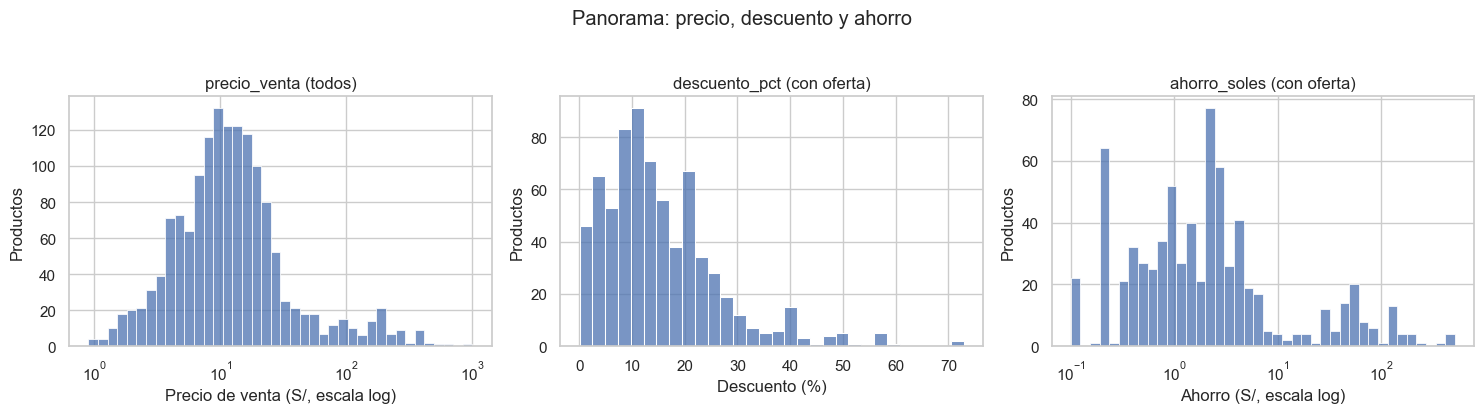

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["precio_venta"], bins=40, ax=axes[0], log_scale=(True, False))
axes[0].set_title("precio_venta (todos)")
axes[0].set_xlabel("Precio de venta (S/, escala log)")

sns.histplot(con_oferta["descuento_pct"], bins=30, ax=axes[1])
axes[1].set_title("descuento_pct (con oferta)")
axes[1].set_xlabel("Descuento (%)")

sns.histplot(con_oferta["ahorro_soles"], bins=40, ax=axes[2], log_scale=(True, False))
axes[2].set_title("ahorro_soles (con oferta)")
axes[2].set_xlabel("Ahorro (S/, escala log)")

for ax in axes:
    ax.set_ylabel("Productos")

fig.suptitle("Panorama: precio, descuento y ahorro", y=1.03)
plt.tight_layout()
plt.savefig(FIGURAS / "f3_panorama.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** El precio de venta es muy asimétrico (la mediana, S/ 11,00, es menos de la mitad de la media, S/ 26,68): pocos productos caros estiran la cola. El descuento, cuando existe, se concentra entre 5 % y 20 % (mediana 13,0 %). El ahorro en soles es el más asimétrico de los tres (mediana S/ 1,75 frente a una media de S/ 14,35): la mayoría de las ofertas son pequeñas en soles, y un grupo chico de productos caros (se ve en la sección 5) eleva la media.

## 3. Objetivo 3 — ¿Dónde hay más ofertas?

Tasa de descuento (% de productos con oferta activa) por categoría y por macro_grupo, con el tamaño de cada grupo indicado.

In [5]:
tasa_categoria = (
    df.groupby("categoria")
    .agg(n=("tiene_descuento", "size"), tasa_pct=("tiene_descuento", lambda s: round(s.mean() * 100, 1)))
    .sort_values("tasa_pct", ascending=False)
)
tasa_macro = (
    df.groupby("macro_grupo")
    .agg(n=("tiene_descuento", "size"), tasa_pct=("tiene_descuento", lambda s: round(s.mean() * 100, 1)))
    .sort_values("tasa_pct", ascending=False)
)
print(tasa_categoria)
print()
print(tasa_macro)

                     n  tasa_pct
categoria                       
Cuidado Personal   150      80.0
Desayunos          150      63.3
Quesos y Fiambres  149      57.7
Abarrotes          150      56.7
Lácteos            150      56.7
Bebidas            150      49.3
Panadería          147      38.8
Congelados         145      38.6
Carnes y Pescados  150      28.0
Frutas y Verduras  150      12.0

                    n  tasa_pct
macro_grupo                    
Cuidado Personal  150      80.0
Envasados         445      53.0
Bebidas           150      49.3
Frescos           746      38.6


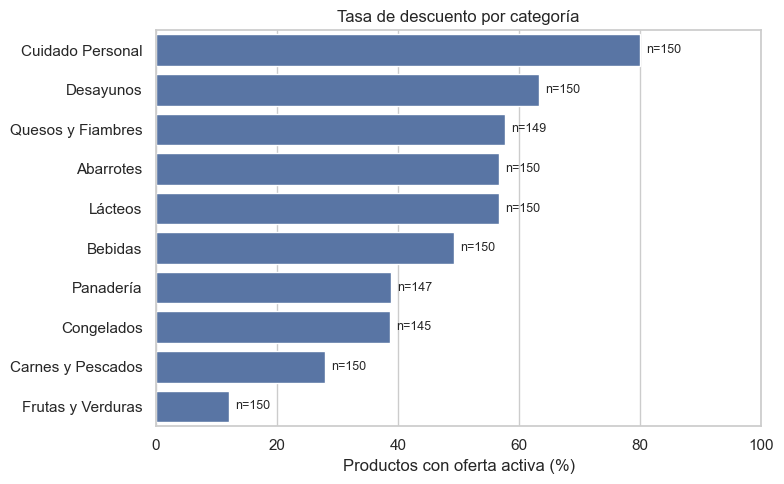

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
orden = tasa_categoria.index
sns.barplot(x=tasa_categoria["tasa_pct"], y=orden, order=orden, ax=ax, color="#4C72B0")
for i, (cat, fila) in enumerate(tasa_categoria.iterrows()):
    ax.text(fila["tasa_pct"] + 1, i, f"n={int(fila['n'])}", va="center", fontsize=9)
ax.set_title("Tasa de descuento por categoría")
ax.set_xlabel("Productos con oferta activa (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.savefig(FIGURAS / "f3_tasa_descuento_categoria.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** Cuidado Personal tiene la tasa de descuento más alta con diferencia (80,0 % de sus 150 productos), y Frutas y Verduras la más baja (12,0 %): la misma brecha de 68 puntos porcentuales que ya se había visto en la Parte I se confirma con el dataset final. Por macro_grupo, Cuidado Personal (80,0 %) está muy por delante de Envasados (53,0 %), Bebidas (49,3 %) y Frescos (38,6 %) — el macro_grupo Frescos queda más bajo porque mezcla Frutas y Verduras con categorías de mayor descuento como Lácteos.

**Limitación.** Es una foto de un solo día (22/09/2026) y de una sola zona de entrega: no dice si una categoría tiene más ofertas *en general*, solo que las tuvo ese día.

## 4. Objetivo 4 — ¿Cuánto se ahorra de verdad?

`rango_descuento` agrupa el tamaño del descuento; `oferta_significativa` (calculada en la sección 1, umbral del contrato: descuento ≥ 10 % y ahorro ≥ S/ 2) separa las ofertas que de verdad mueven el bolsillo de las simbólicas.

In [7]:
print("rango_descuento (todo el dataset):")
dist_rango = df["rango_descuento"].value_counts()
print(pd.concat([dist_rango, (dist_rango / len(df) * 100).round(1).rename("pct")], axis=1))

print("\noferta_significativa por categoría (%):")
tabla_os = (df.groupby("categoria")["oferta_significativa"].mean() * 100).round(1).sort_values(ascending=False)
print(tabla_os)

corr = con_oferta[["descuento_pct", "ahorro_soles"]].corr().iloc[0, 1]
print(f"\ncorrelación descuento_pct vs ahorro_soles (con oferta): {corr:.2f}")

rango_descuento (todo el dataset):
                    count   pct
rango_descuento                
Sin descuento         773  51.8
Moderado (10%-25%)    366  24.5
Bajo (<10%)           249  16.7
Alto (>25%)           103   6.9

oferta_significativa por categoría (%):
categoria
Cuidado Personal     74.0
Desayunos            33.3
Congelados           32.4
Quesos y Fiambres    24.2
Abarrotes            16.0
Lácteos              14.0
Carnes y Pescados    13.3
Panadería             6.1
Bebidas               2.7
Frutas y Verduras     2.7
Name: oferta_significativa, dtype: float64

correlación descuento_pct vs ahorro_soles (con oferta): 0.64


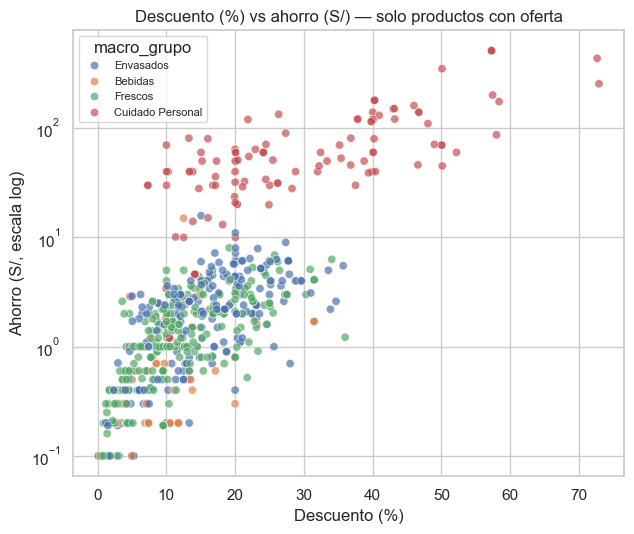

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.scatterplot(data=con_oferta, x="descuento_pct", y="ahorro_soles", hue="macro_grupo", alpha=0.7, ax=ax)
ax.set_yscale("log")
ax.set_title("Descuento (%) vs ahorro (S/) — solo productos con oferta")
ax.set_xlabel("Descuento (%)")
ax.set_ylabel("Ahorro (S/, escala log)")
ax.legend(title="macro_grupo", fontsize=8)
plt.tight_layout()
plt.savefig(FIGURAS / "f3_dispersion_descuento_ahorro.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** El 51,8 % del catálogo no tiene oferta; del resto, los descuentos "Moderado (10%-25%)" son los más comunes (24,5 % del total) y "Alto (>25%)" los menos (6,9 %). La correlación entre descuento_pct y ahorro_soles es de 0,64: positiva pero lejos de perfecta, porque el ahorro en soles también depende del precio del producto. Esto separa dos patrones: 12 productos con descuento ≥ 30 % pero ahorro menor a S/ 5 (descuento alto, simbólico en soles) y 19 productos con descuento menor a 20 % pero ahorro de S/ 20 o más (moderado, pero en un producto caro). `oferta_significativa` resume esto: solo el 21,9 % del catálogo (326 de 1491) tiene una oferta que cumple ambos umbrales a la vez, y Cuidado Personal vuelve a liderar (74,0 %), muy por delante de Desayunos (33,3 %) y Congelados (32,4 %).

**Limitación.** Los umbrales (≥10 % y ≥S/ 2) son los que acordó el equipo; con otro umbral la proporción de "oferta significativa" cambia.

## 5. Anomalía: Cuidado Personal

La sección anterior ya muestra que Cuidado Personal concentra las ofertas más grandes. Aquí se mira de cerca qué productos son.

In [9]:
ahorro_categoria = df.groupby("categoria")["ahorro_soles"].agg(["mean", "median"]).round(2).sort_values("mean", ascending=False)
print(ahorro_categoria)

top10 = df.nlargest(10, "ahorro_soles")[["nombre", "categoria", "precio_regular", "precio_venta", "ahorro_soles", "descuento_pct"]]
top10

                    mean  median
categoria                       
Cuidado Personal   61.35   39.96
Desayunos           1.82    0.50
Congelados          1.14    0.00
Quesos y Fiambres   1.10    0.50
Abarrotes           0.88    0.25
Lácteos             0.77    0.19
Carnes y Pescados   0.68    0.00
Bebidas             0.47    0.00
Panadería           0.39    0.00
Frutas y Verduras   0.13    0.00


,nombre,categoria,precio_regular,precio_venta,ahorro_soles,descuento_pct
522,Zeaxan 6 Pack Cuidado para Tu Salud Ocular,Cuidado Personal,894.0,382.0,512.0,57.27
598,CALMANO - 6 pack - CAPSULAS para VARICES y HEM...,Cuidado Personal,894.0,382.0,512.0,57.27
599,CALMANO capsulas pack x 3 + CALMANO crema pack...,Cuidado Personal,894.0,382.0,512.0,57.27
597,MUTANT MASS DE 5LB VAINILLA - GANADOR MASA,Cuidado Personal,599.0,164.0,435.0,72.62
451,Secadora de Cabello SIEGEN SG-B3160 Blanco,Cuidado Personal,699.0,349.0,350.0,50.07
575,PROTEÍNA WHEY PRO 1.1 KG COOKIES + CREATINA UN...,Cuidado Personal,350.0,94.9,255.1,72.89
568,PROTEÍNA WHEY PRO 5 KG CHOCOLATE y muñequera,Cuidado Personal,350.0,149.0,201.0,57.43
466,HAIREX para Caida de Cabello 3 Pack,Cuidado Personal,447.0,267.0,180.0,40.27
517,Glyconorm 3 Pack Alivia y Controla Síntomas de...,Cuidado Personal,447.0,267.0,180.0,40.27
524,Flexacil Ultra 3 Pack para Molestias Articular...,Cuidado Personal,447.0,267.0,180.0,40.27


**Interpretación.** El ahorro promedio en Cuidado Personal es S/ 61,35, frente a S/ 1,82 en la siguiente categoría (Desayunos) y S/ 0,82 en el resto del catálogo junto. Dentro de la propia categoría, la mediana (S/ 39,96) es bastante menor que la media: unos pocos productos muy caros (suplementos, proteínas en polvo y una secadora de cabello, todos sobre S/ 180 de ahorro) estiran el promedio. Los 10 mayores ahorros del catálogo entero son, sin excepción, de Cuidado Personal — coherente con que esa categoría ya tenía la mediana de precio más alta (sección 3 del notebook de P1).

**Limitación.** Son 150 productos por categoría sin muestreo aleatorio (los primeros que muestra el sitio); no se puede afirmar que esta brecha se mantenga en todo el catálogo real de PlazaVea.

## 6. Segmentación: ¿los productos premium se rebajan más o menos?

`segmento_precio` (sección 1) divide cada categoría en terciles de precio_venta. Se cruza con `macro_grupo` y la tasa de descuento para ver si el patrón es el mismo en todas partes.

segmento_precio   Económico  Medio  Premium
macro_grupo                                
Bebidas                62.7   40.8     44.0
Cuidado Personal       67.3   83.3     90.0
Envasados              54.7   49.3     55.0
Frescos                37.3   43.8     34.6


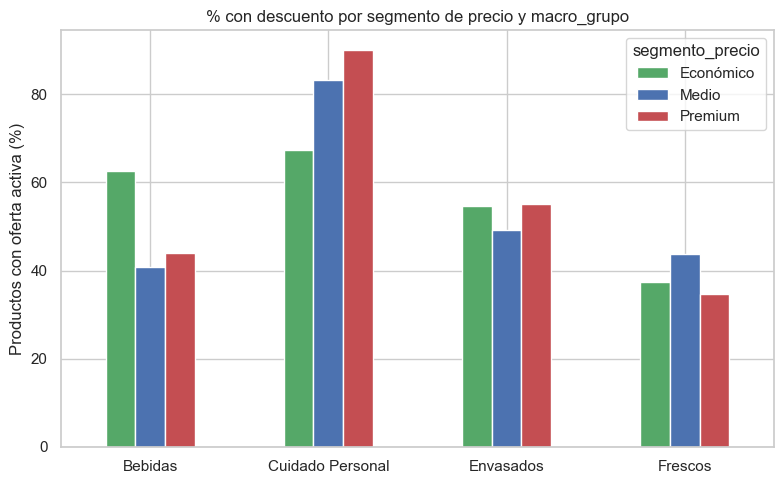

In [10]:
seg = (
    df.groupby(["macro_grupo", "segmento_precio"], observed=True)["tiene_descuento"]
    .mean().mul(100).round(1).unstack()
)
print(seg)

fig, ax = plt.subplots(figsize=(8, 5))
seg.plot(kind="bar", ax=ax, color=["#55A868", "#4C72B0", "#C44E52"])
ax.set_title("% con descuento por segmento de precio y macro_grupo")
ax.set_xlabel("")
ax.set_ylabel("Productos con oferta activa (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
ax.legend(title="segmento_precio")
plt.tight_layout()
plt.savefig(FIGURAS / "f3_segmentacion_precio.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación.** No hay un patrón único: depende del macro_grupo. En Cuidado Personal los productos Premium se rebajan claramente más (90,0 % vs 67,3 % en Económico); en Bebidas pasa lo contrario (Económico 62,7 % vs Premium 44,0 %); en Frescos y Envasados la diferencia entre segmentos es chica y sin una dirección clara (37-44 % y 49-55 % respectivamente). En conjunto, el precio del producto por sí solo no predice si tiene oferta (48,1 % Económico vs 47,4 % Premium): lo que sí importa es a qué macro_grupo pertenece (sección 3).

## 7. Bitácora de decisiones

In [11]:
nuevas_decisiones = pd.DataFrame([
    {
        "paso": "P3.1 oferta_significativa y segmento_precio",
        "decision": "Se calculan en este notebook (vía src/features.py) porque el dataset final de P2 no las incluye",
        "justificacion": "El objetivo 4 (dispersión y segmentación) las necesita; ambas estaban definidas en el contrato de datos del equipo",
        "alternativa_descartada": "Pedir a P2 que reabra su notebook y las agregue (retrasa el análisis de P3 sin necesidad: la definición ya estaba acordada)",
        "filas_antes": len(df), "filas_despues": len(df), "delta_filas": 0,
    },
    {
        "paso": "P3.2 Prueba estadística del objetivo 3",
        "decision": "No se corre una prueba chi-cuadrado; la diferencia entre categorías se reporta solo de forma descriptiva",
        "justificacion": "Es un paso opcional del plan y la brecha observada (80,0% vs 12,0%) ya es grande; scipy no está entre las dependencias del proyecto",
        "alternativa_descartada": "Agregar scipy solo para esta prueba opcional (nueva dependencia para un resultado que ya es evidente)",
        "filas_antes": len(df), "filas_despues": len(df), "delta_filas": 0,
    },
])

ruta_bitacora = DOCS / "bitacora_decisiones.csv"
bitacora = pd.read_csv(ruta_bitacora)
ya_registradas = bitacora["paso"].isin(nuevas_decisiones["paso"])
if ya_registradas.any():
    bitacora = bitacora[~bitacora["paso"].isin(nuevas_decisiones["paso"])]  # evita duplicar si se vuelve a correr
bitacora = pd.concat([bitacora, nuevas_decisiones], ignore_index=True)
bitacora.to_csv(ruta_bitacora, index=False, encoding="utf-8", lineterminator="
")  # evita CRLF en Windows
print(f"bitácora actualizada: {len(bitacora)} decisiones en total")
bitacora.tail(2)

bitácora actualizada: 11 decisiones en total


,paso,decision,justificacion,alternativa_descartada,filas_antes,filas_despues,delta_filas
9,P3.1 oferta_significativa y segmento_precio,Se calculan en este notebook (vía src/features...,El objetivo 4 (dispersión y segmentación) las ...,Pedir a P2 que reabra su notebook y las agregu...,1491,1491,0
10,P3.2 Prueba estadística del objetivo 3,No se corre una prueba chi-cuadrado; la difere...,Es un paso opcional del plan y la brecha obser...,Agregar scipy solo para esta prueba opcional (...,1491,1491,0


## 8. Insumos para las conclusiones (objetivos 3 y 4)

- **Objetivo 3.** Cuidado Personal concentra la mayor tasa de descuento (80,0 % de 150 productos) y Frutas y Verduras la menor (12,0 %). *Limitación:* una sola fecha y zona de entrega, sin muestreo aleatorio.
- **Objetivo 4.** El 48,2 % del catálogo tiene oferta, pero solo el 21,9 % es una oferta significativa (≥10 % y ≥S/ 2); la mediana de ahorro real es de solo S/ 1,75, salvo en Cuidado Personal (mediana S/ 39,96). *Limitación:* los umbrales de "significativa" son una definición del equipo, no un estándar externo.

## 9. Verificación

Confirma que las figuras quedaron guardadas y que `run_pipeline.py` (que usa las mismas funciones de `src/`) sigue corriendo de punta a punta.

In [12]:
figuras_esperadas = ["f3_panorama.png", "f3_tasa_descuento_categoria.png",
                     "f3_dispersion_descuento_ahorro.png", "f3_segmentacion_precio.png"]
for nombre in figuras_esperadas:
    ruta = FIGURAS / nombre
    print(("OK   " if ruta.exists() else "FALLA"), ruta)

OK    ..\docs\figures\f3_panorama.png
OK    ..\docs\figures\f3_tasa_descuento_categoria.png
OK    ..\docs\figures\f3_dispersion_descuento_ahorro.png
OK    ..\docs\figures\f3_segmentacion_precio.png


## 10. Conclusiones de P3

**Qué se encontró**
- La tasa de descuento varía mucho por categoría (80,0 % en Cuidado Personal, 12,0 % en Frutas y Verduras) y ese orden se mantiene al mirarlo por macro_grupo.
- El ahorro real suele ser chico: la mitad de las ofertas del catálogo ahorran S/ 1,75 o menos. Cuidado Personal es la excepción clara, con ofertas de hasta S/ 512 en productos de alto precio (suplementos, proteínas, un secador).
- Solo 1 de cada 5 productos del catálogo tiene una oferta "significativa" a la vez en porcentaje y en soles.
- Que un producto sea Económico, Medio o Premium dentro de su categoría no predice por sí solo si tiene descuento: el patrón depende del macro_grupo (en Cuidado Personal sí hay más descuento en lo Premium; en Bebidas, al revés).

**Qué se decidió y por qué**
- `oferta_significativa` y `segmento_precio` se calcularon en este notebook (no venían en el dataset de P2) reutilizando `src/features.py`, para no duplicar la lógica entre el notebook y `run_pipeline.py`.
- No se corrió una prueba chi-cuadrado (paso opcional del plan): la diferencia entre categorías del objetivo 3 ya es grande y clara de forma descriptiva.

**Para P4 y P5**
- `src/ingestion.py`, `src/preprocessing.py` y `src/features.py` ya existen y `run_pipeline.py` (raíz del repo) regenera el dataset final y la base SQLite con un solo comando — útil para la sección 5 del informe (diseño del pipeline) y para reproducir el proyecto desde cero.
- Las 4 figuras de esta sección están en `docs/figures/f3_*.png`, listas para las diapositivas y para la sección 8 del informe.